In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt


PERFORMANCE_DIR = Path("performance-record")

all_results = []

csv_files = sorted(PERFORMANCE_DIR.glob("*.csv"))

if not csv_files:
    raise FileNotFoundError(f"No CSV files found in {PERFORMANCE_DIR}")

for csv_file in csv_files:
    df = pd.read_csv(
        csv_file,
        usecols=["accuracy", "fold", "window_size","misclassified_devices"]
    )

    avg_accuracy = (
        df
        .groupby("window_size", as_index=False)
        .agg(
            avg_accuracy=("accuracy", "mean"),
            num_folds=("fold", "nunique"),
        )
        .sort_values("window_size")
    )

    avg_accuracy["configuration"] = csv_file.stem

    all_results.append(avg_accuracy)

performance_summary = pd.concat(all_results, ignore_index=True)

In [2]:
DATASET_FOLDER = "../../../dataset/processed-data"
DEVICE_MAPPING_FOLDER = DATASET_FOLDER + "/device-mapping"
INPUT_FOLDER = DATASET_FOLDER + "/input-data"
DATASET1 = "dataset1"
DATASET2 = "dataset2"

In [3]:
MAPPING_LIST_1 = f"{DEVICE_MAPPING_FOLDER}/{DATASET1}/list_of_devices_processed.csv"
device_mapping_1 = pd.read_csv(MAPPING_LIST_1)
device_dict_1 = (
    device_mapping_1
    .set_index("mac_address")
    .drop(columns=["mac_address"], errors="ignore")
    .to_dict(orient="index")
)
device_dict_1

{'d0:52:a8:00:67:5e': {'device_name': 'Smart Things',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'hub',
  'vendor': 'Samsung SmartThings'},
 '44:65:0d:56:cc:d3': {'device_name': 'Amazon Echo',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'smart speaker',
  'vendor': 'Amazon'},
 '70:ee:50:18:34:43': {'device_name': 'Netatmo Welcome',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Netatmo'},
 'f4:f2:6d:93:51:f1': {'device_name': 'TP-Link Day Night Cloud camera',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'TP-Link'},
 '00:16:6c:ab:6b:88': {'device_name': 'Samsung SmartCam',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Samsung'},
 '30:8c:fb:2f:e4:b2': {'device_name': 'Dropcam',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Dropcam'},
 '00:62:6e:51:27:2e': {'device_name': 'Insteon Camera Wired',
  'ip_address': 

In [4]:
all_configs = [csv_file.stem for csv_file in csv_files]
all_configs

['2labels-drop-router-and-hub-with-3-features',
 '2labels-drop-router-and-hub',
 '2labels-drop-router-camera',
 '2labels-drop-router-with-3-features',
 '2labels-drop-router',
 '3labels-drop-router-health-monitor-type-3',
 '3labels-drop-router-type3-camera',
 '3labels-drop-router-with-3-features-camera-device',
 '3labels-drop-router-with-3-features-health-device']

In [5]:
configs_label = {
    '2labels-drop-router-and-hub-with-3-features':{
        'L': 2,
        'F': 3,
        'X': "router_and_hub"
    },
    '2labels-drop-router-and-hub':{
        'L': 2,
        'F': 2,
        'X': "router_and_hub"
    },
    '2labels-drop-router-camera':{
        'L': 2,
        'F': 2,
        'X': "router_and_camera"
    },
    '2labels-drop-router-with-3-features':{
        'L': 2,
        'F': 3,
        'X': "router"
    },
    '2labels-drop-router':{
        'L': 2,
        'F': 2,
        'X': "router"
    },
    '3labels-drop-router-health-monitor-type-3':{
        'L': 3,
        'F': 2,
        'X': "router",
        'A': "health_monitor_type_3"
    },
    '3labels-drop-router-type3-camera':{
        'L': 3,
        'F': 2,
        'X': "router",
        'A': "camera_type_3"
    },
    '3labels-drop-router-with-3-features-camera-device':{
        'L': 3,
        'F': 3,
        'X': "router",
        'A': "camera_type_3"
    },
    '3labels-drop-router-with-3-features-health-device':{
        'L': 3,
        'F': 3,
        'X': "router",
        'A': "health_monitor_type_3"
    }
}

In [6]:
def get_config_label(config_name):
    config = configs_label.get(config_name, {})
    label_parts = [f"{key}={value}" for key, value in config.items()]
    return ",".join(label_parts) if label_parts else config_name

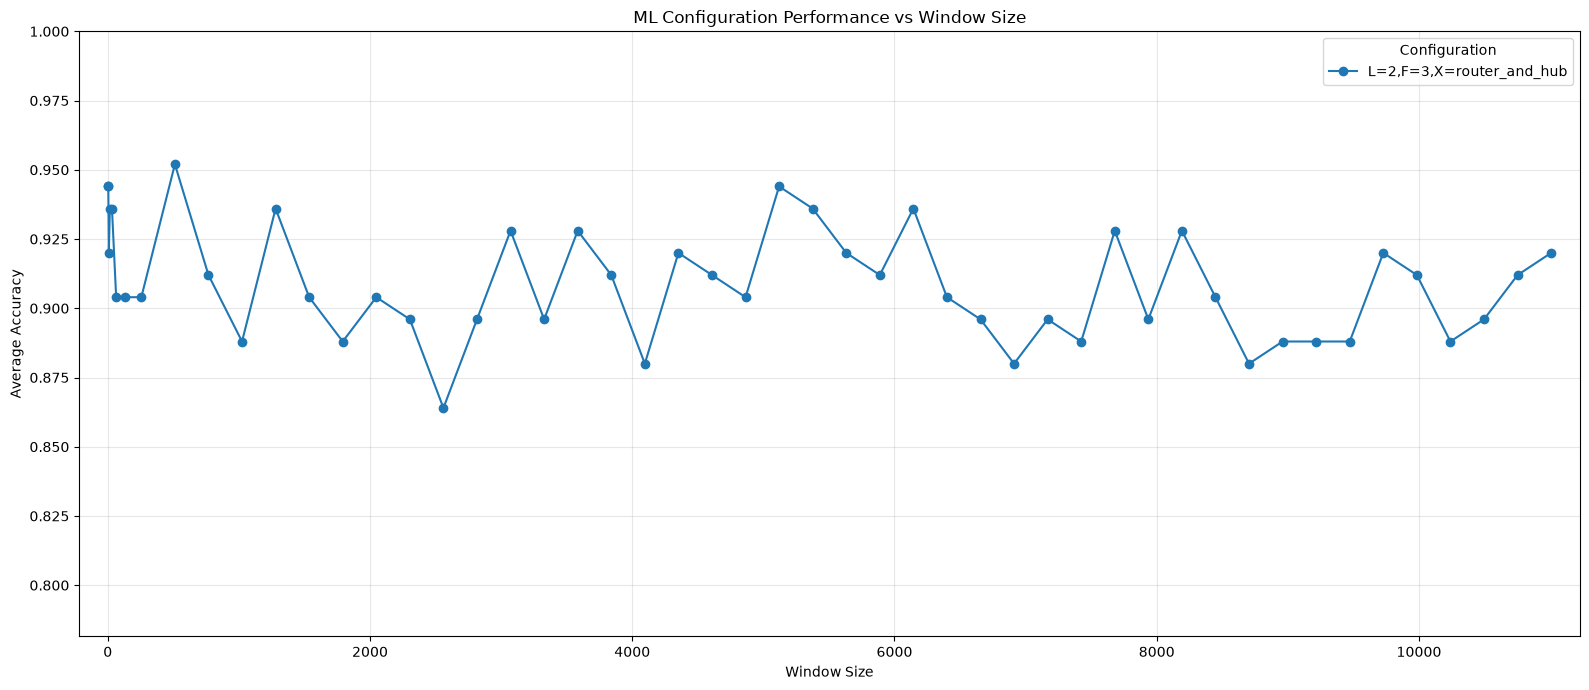

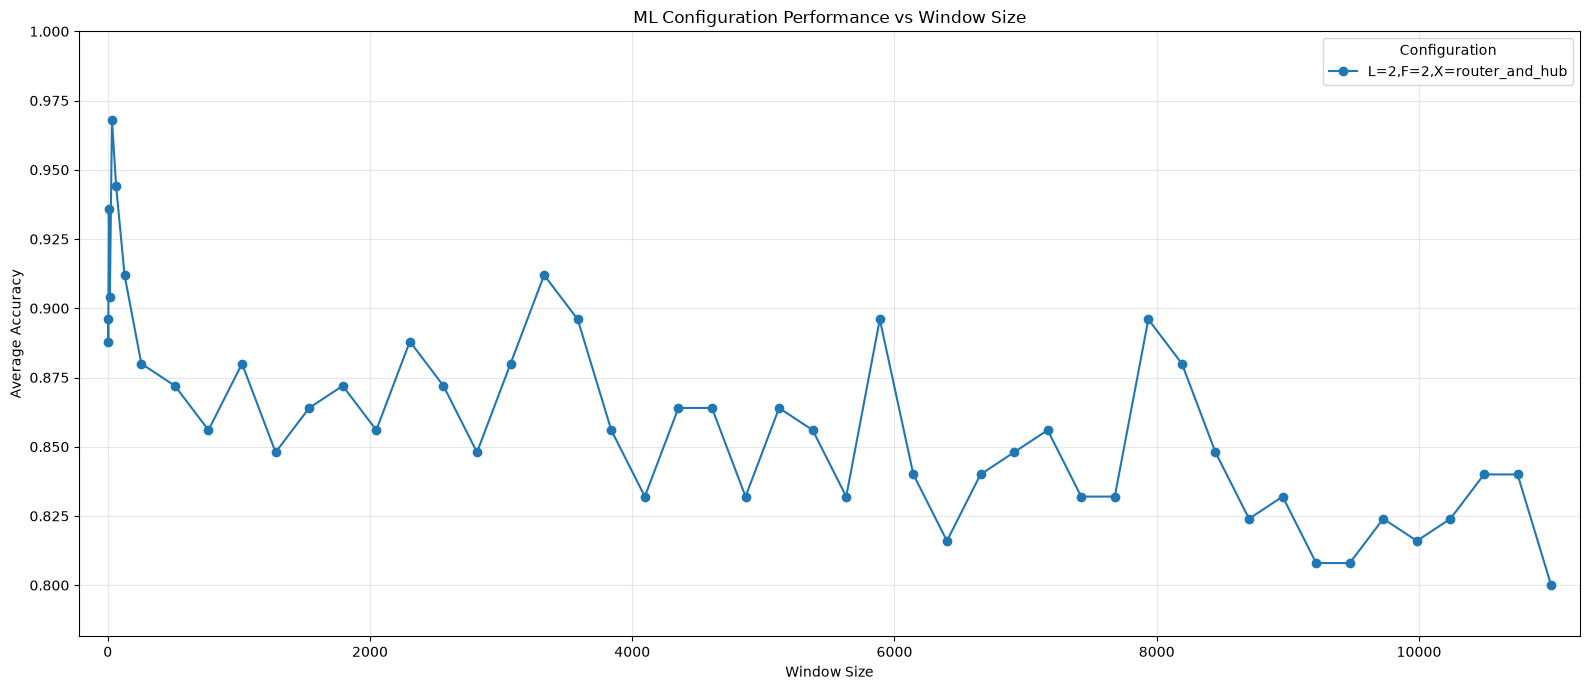

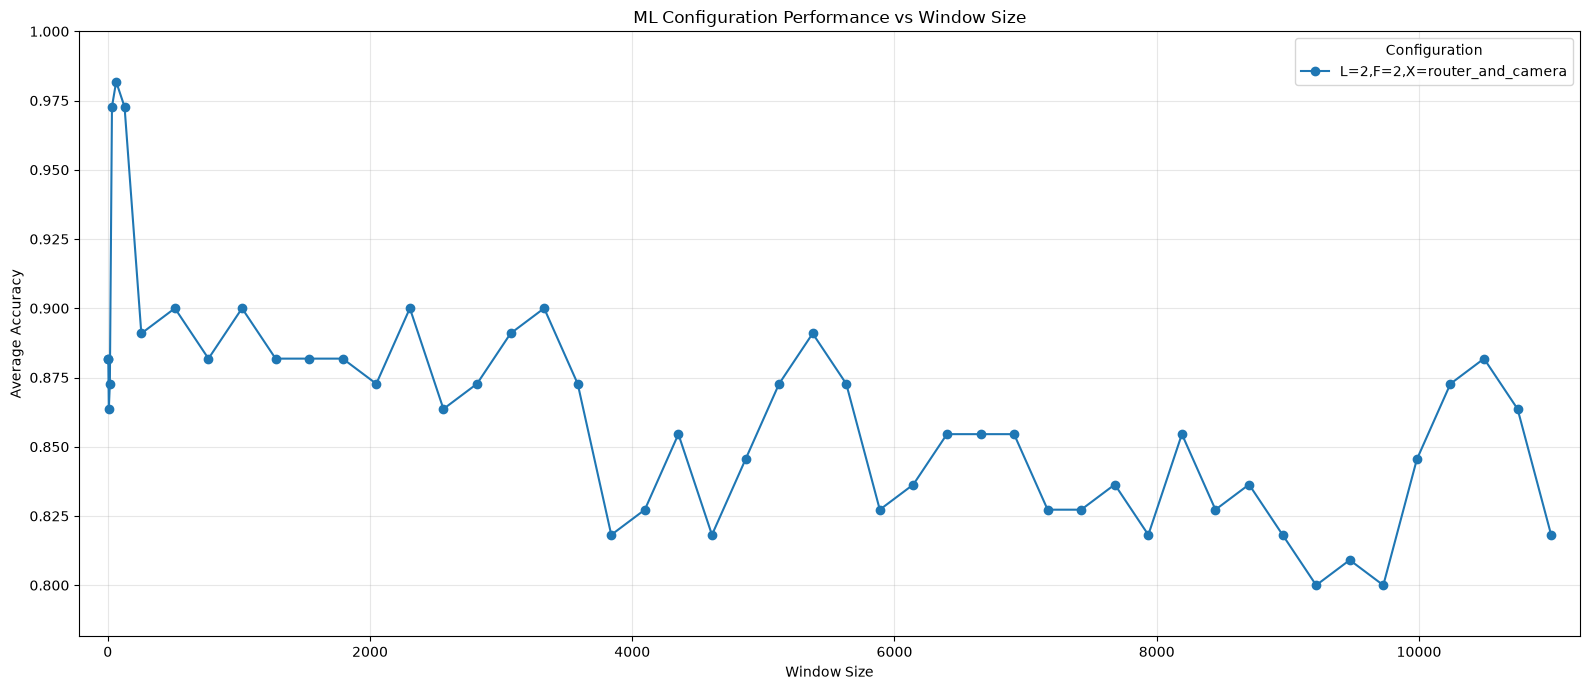

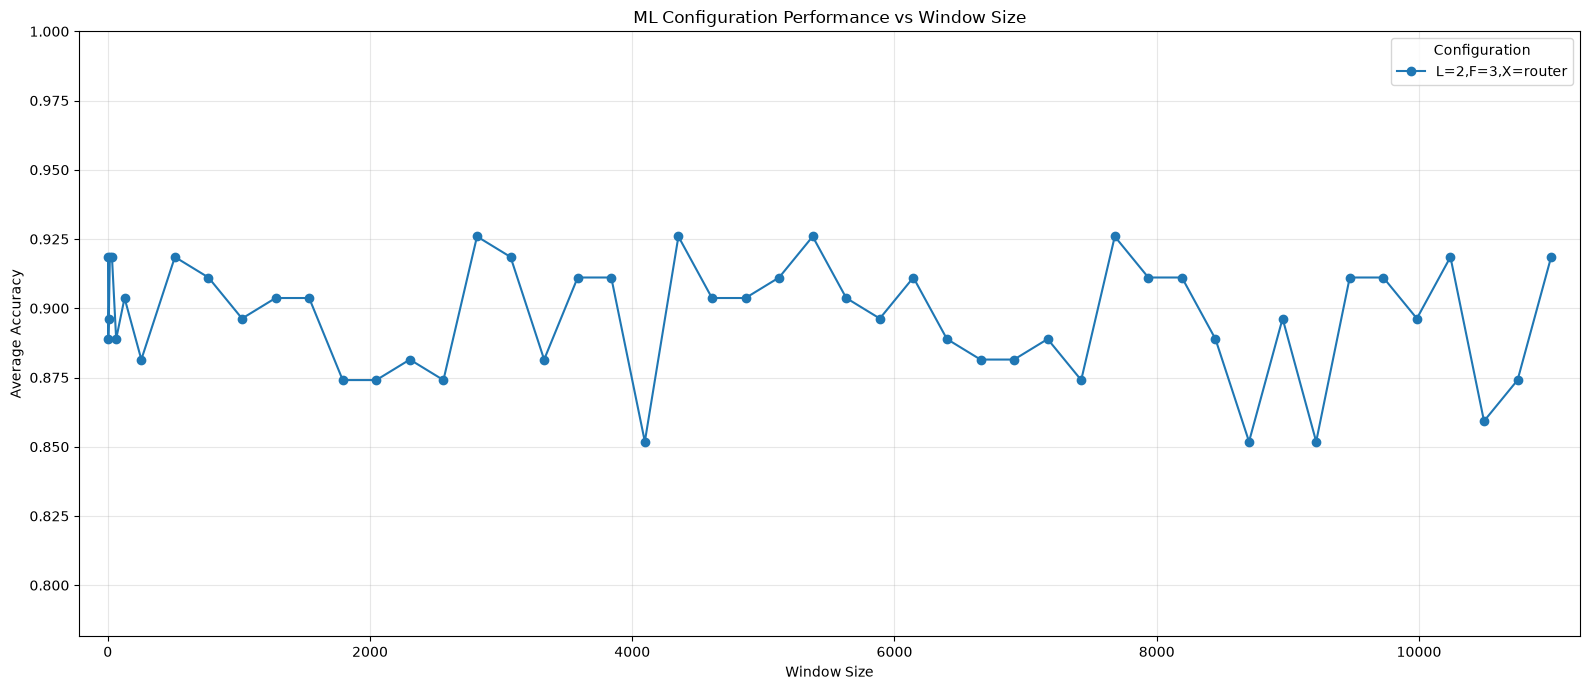

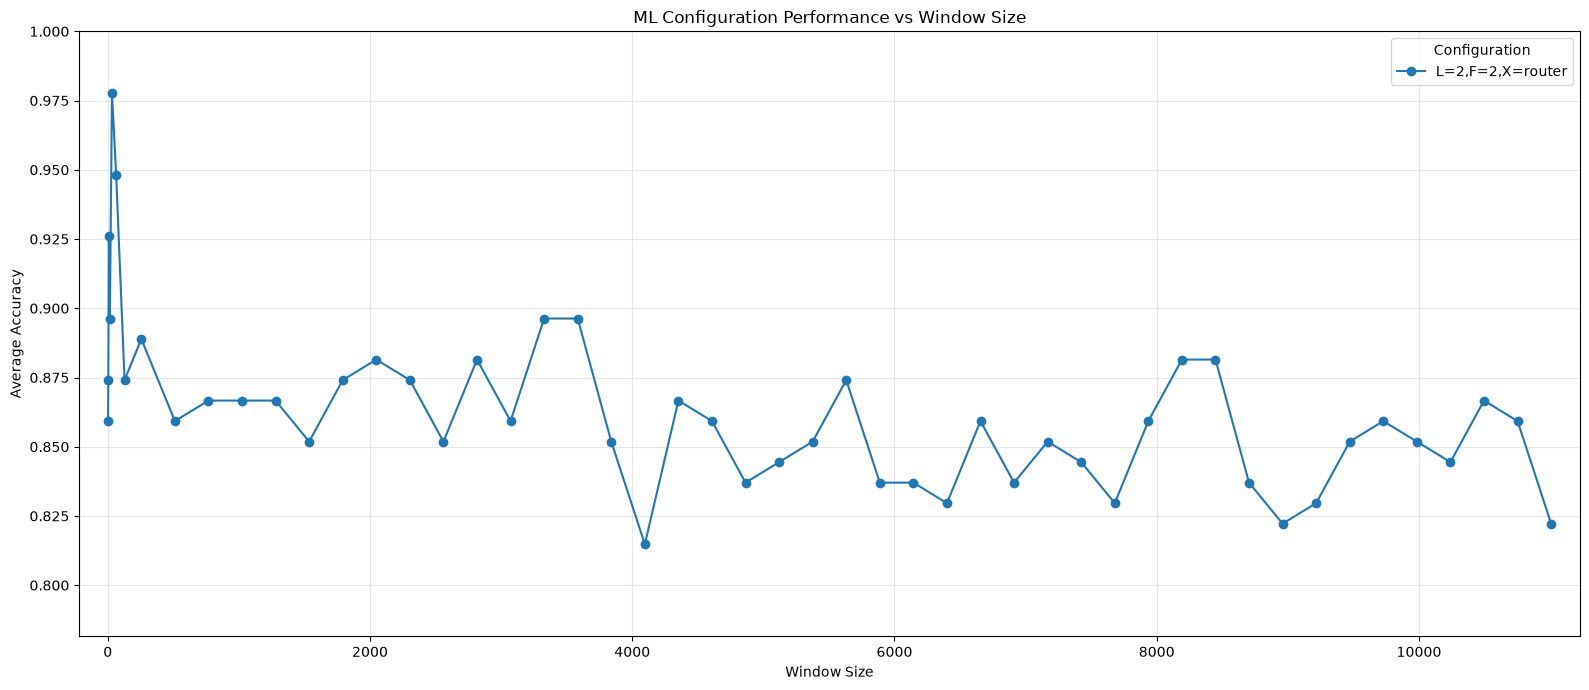

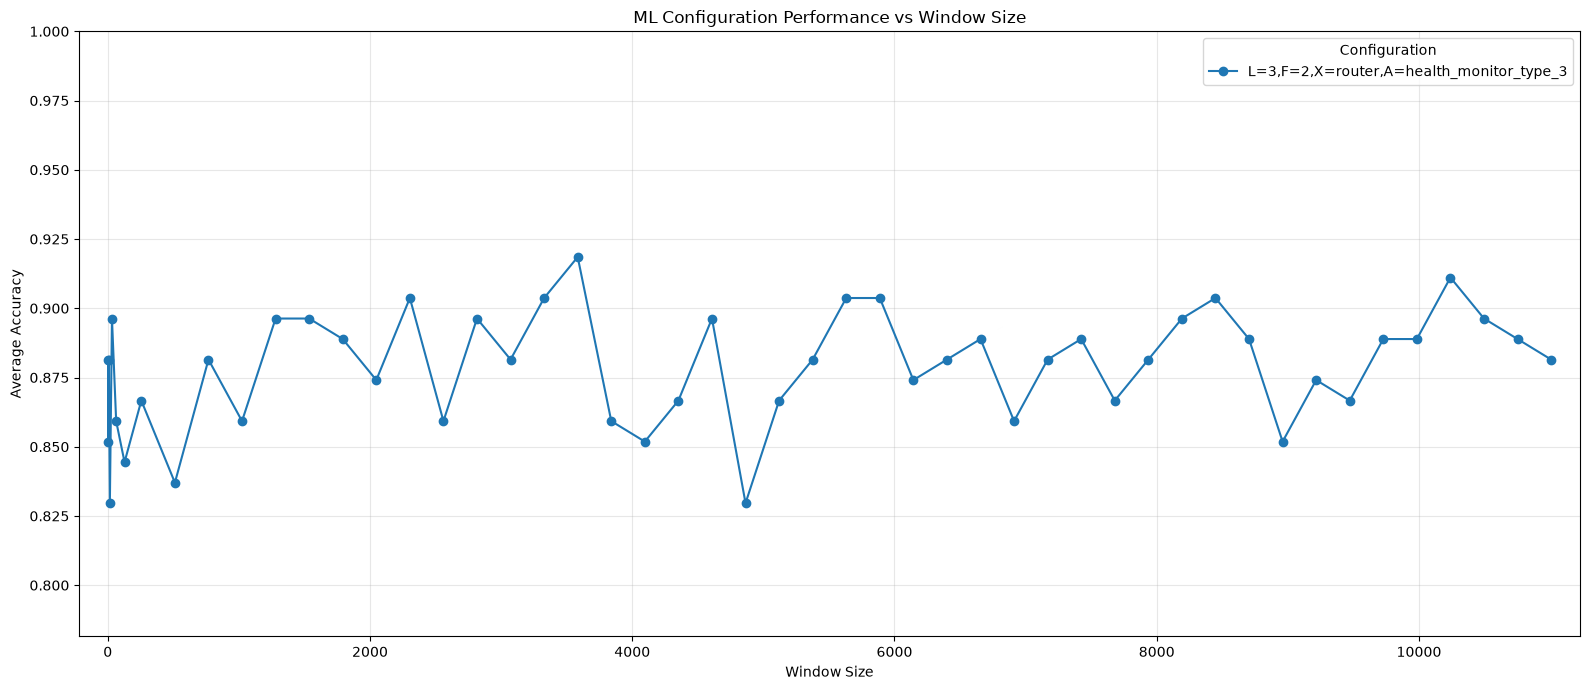

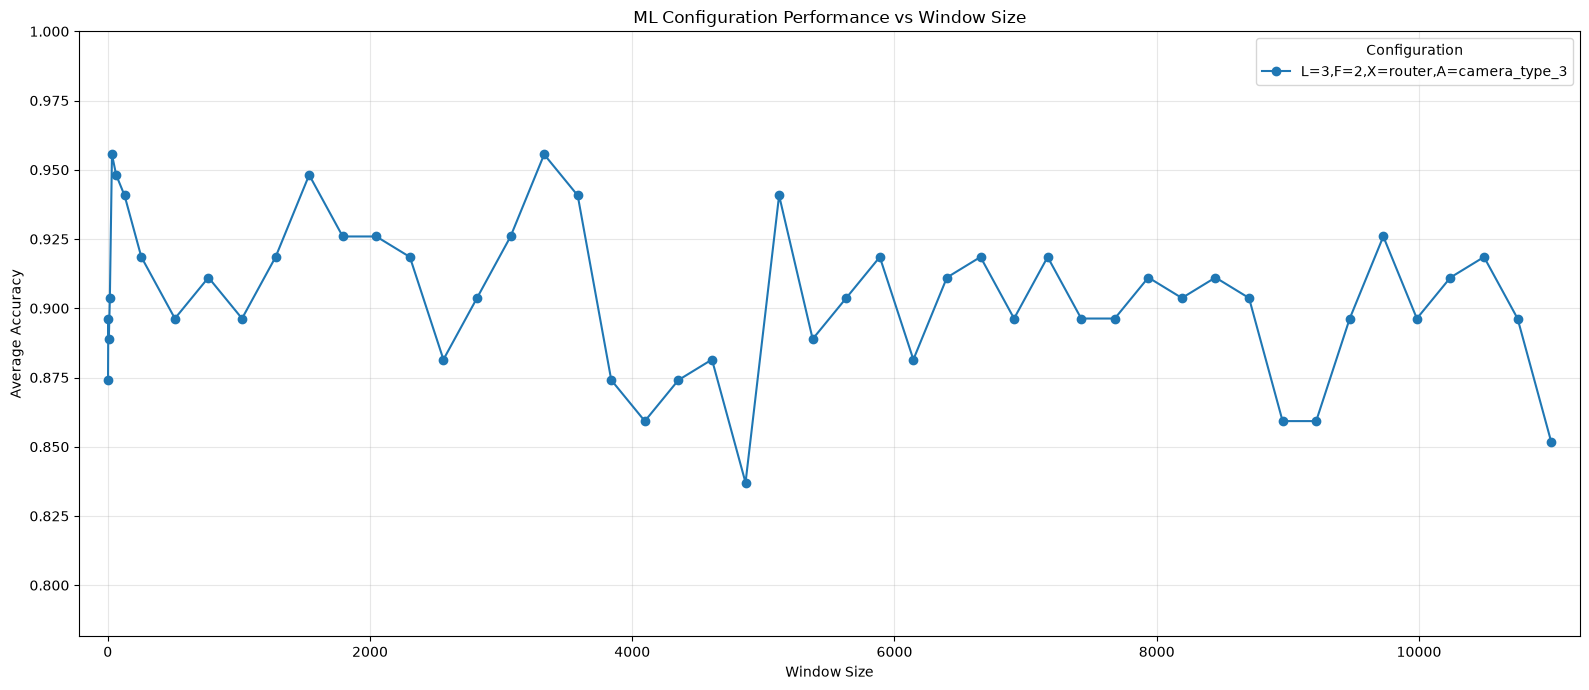

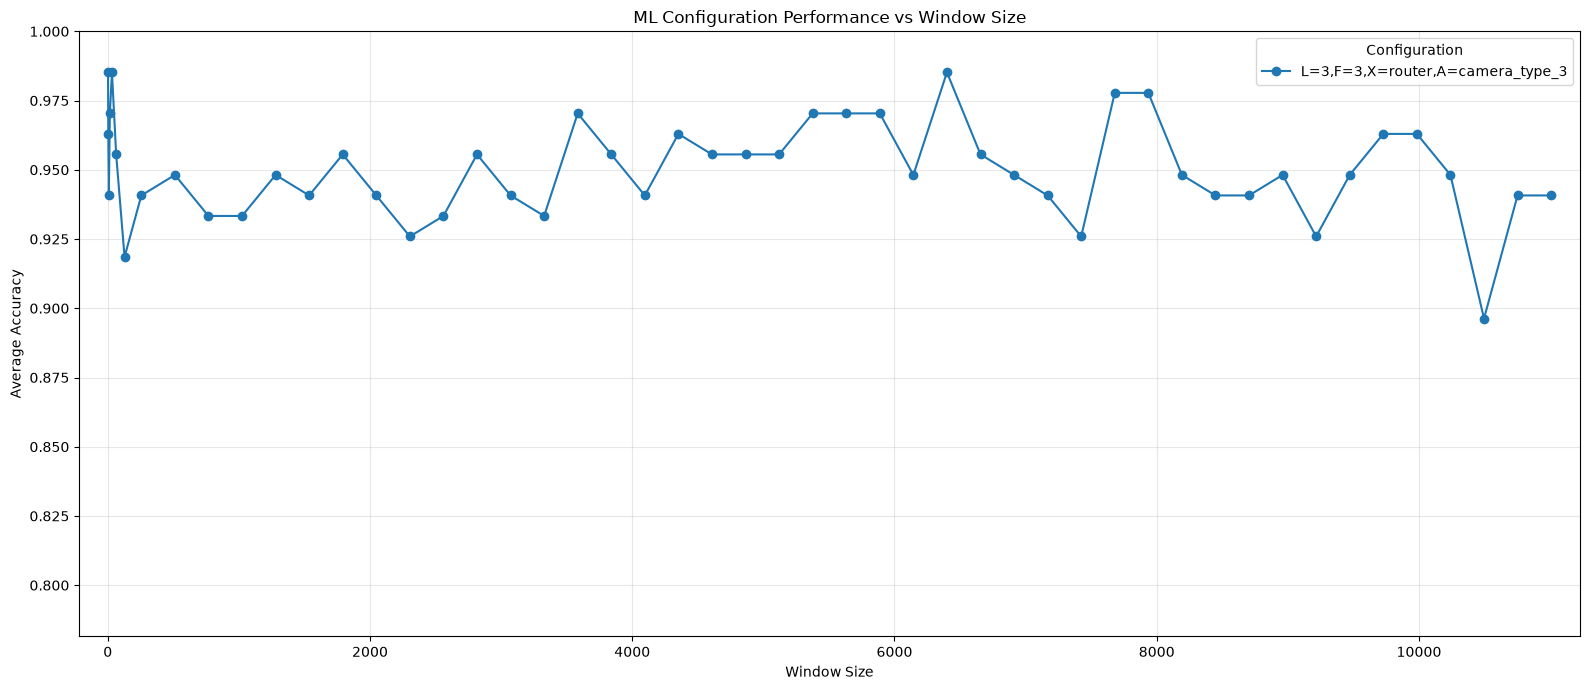

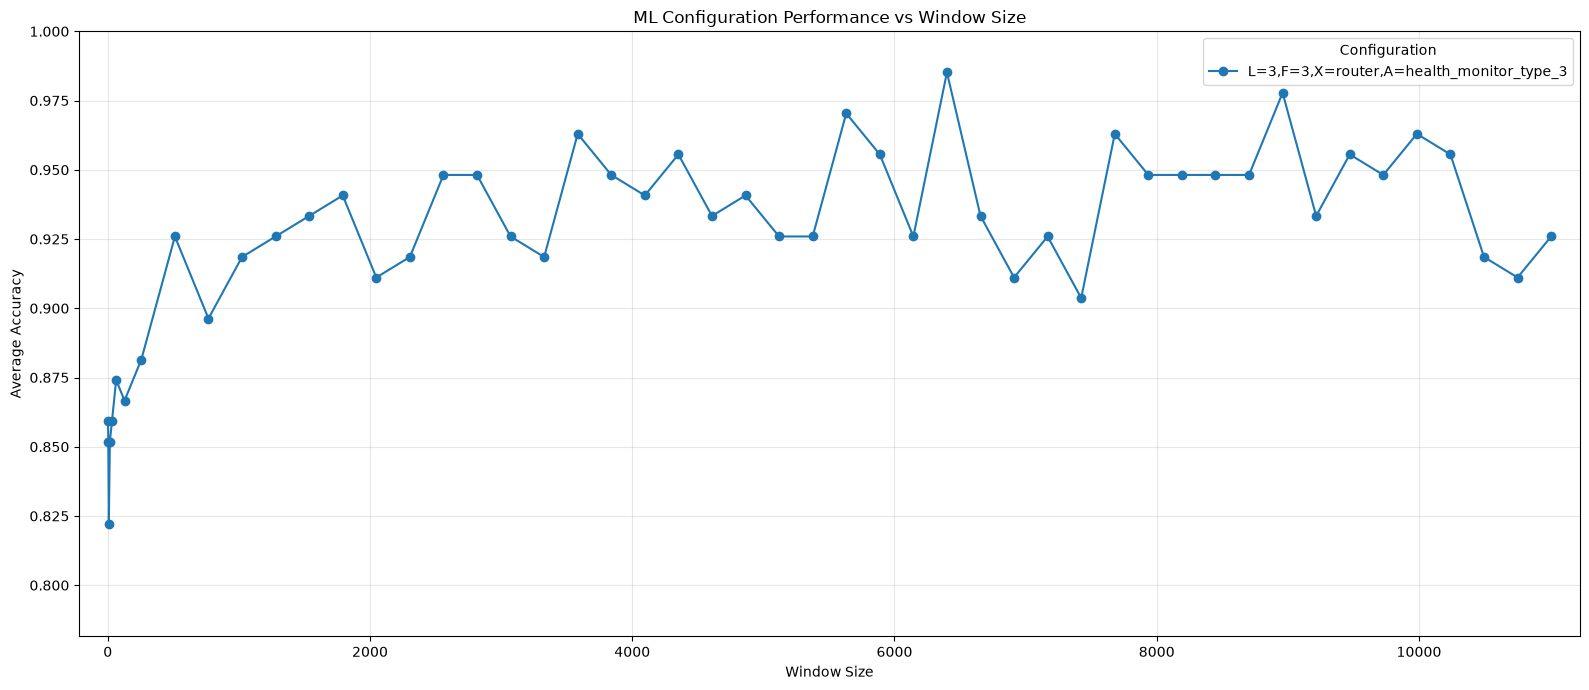

In [7]:
def plot_performance(performance_df: pd.DataFrame):
    for configuration, df in performance_df.groupby(
        "configuration",
        sort=False
    ):
        df = df.sort_values("window_size")
        plt.figure(figsize=(16, 7))
        plt.plot(
            df["window_size"],
            df["avg_accuracy"],
            marker="o",
            label=get_config_label(configuration),
        )

        min_x = performance_df["window_size"].min()
        max_x = performance_df["window_size"].max()

        min_y = performance_df["avg_accuracy"].min()
        max_y = performance_df["avg_accuracy"].max()

        # Add small padding around the actual data
        x_padding = (max_x - min_x) * 0.02
        y_padding = (max_y - min_y) * 0.10

        plt.xlim(
            min_x - x_padding,
            max_x + x_padding
        )

        plt.ylim(
            max(0, min_y - y_padding),
            min(1, max_y + y_padding)
        )

        plt.xlabel("Window Size")
        plt.ylabel("Average Accuracy")
        plt.title("ML Configuration Performance vs Window Size")

        plt.grid(True, alpha=0.3)
        plt.legend(title="Configuration")
        plt.tight_layout()

        plt.show()

plot_performance(performance_summary)

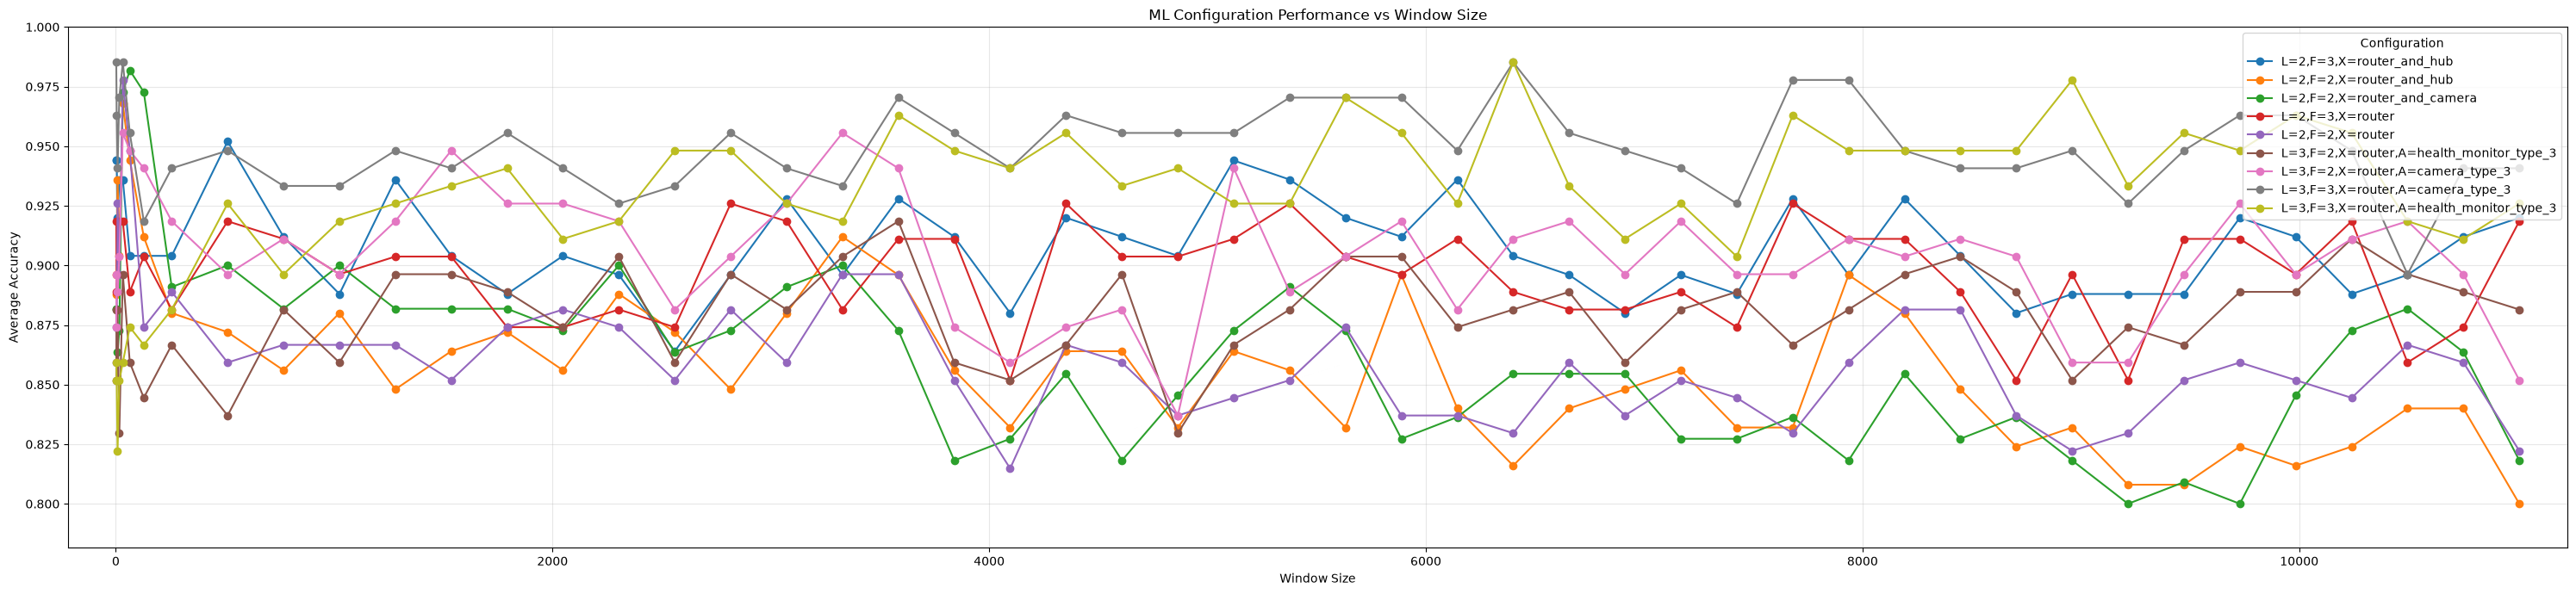

In [8]:
def plot_performance(performance_df: pd.DataFrame, title: str = "ML Configuration Performance vs Window Size"):
    plt.figure(figsize=(30, 7))

    for configuration, df in performance_df.groupby(
        "configuration",
        sort=False
    ):
        df = df.sort_values("window_size")

        plt.plot(
            df["window_size"],
            df["avg_accuracy"],
            marker="o",
            label=get_config_label(configuration),
        )

    min_x = performance_df["window_size"].min()
    max_x = performance_df["window_size"].max()

    min_y = performance_df["avg_accuracy"].min()
    max_y = performance_df["avg_accuracy"].max()

    # Add small padding around the actual data
    x_padding = (max_x - min_x) * 0.02
    y_padding = (max_y - min_y) * 0.10

    plt.xlim(
        min_x - x_padding,
        max_x + x_padding
    )

    plt.ylim(
        max(0, min_y - y_padding),
        min(1, max_y + y_padding)
    )

    plt.xlabel("Window Size")
    plt.ylabel("Average Accuracy")
    plt.title(title)

    plt.grid(True, alpha=0.3)
    plt.legend(title="Configuration")
    plt.tight_layout()

    plt.show()
plot_performance(performance_summary)

## Performance between config with 2 labels

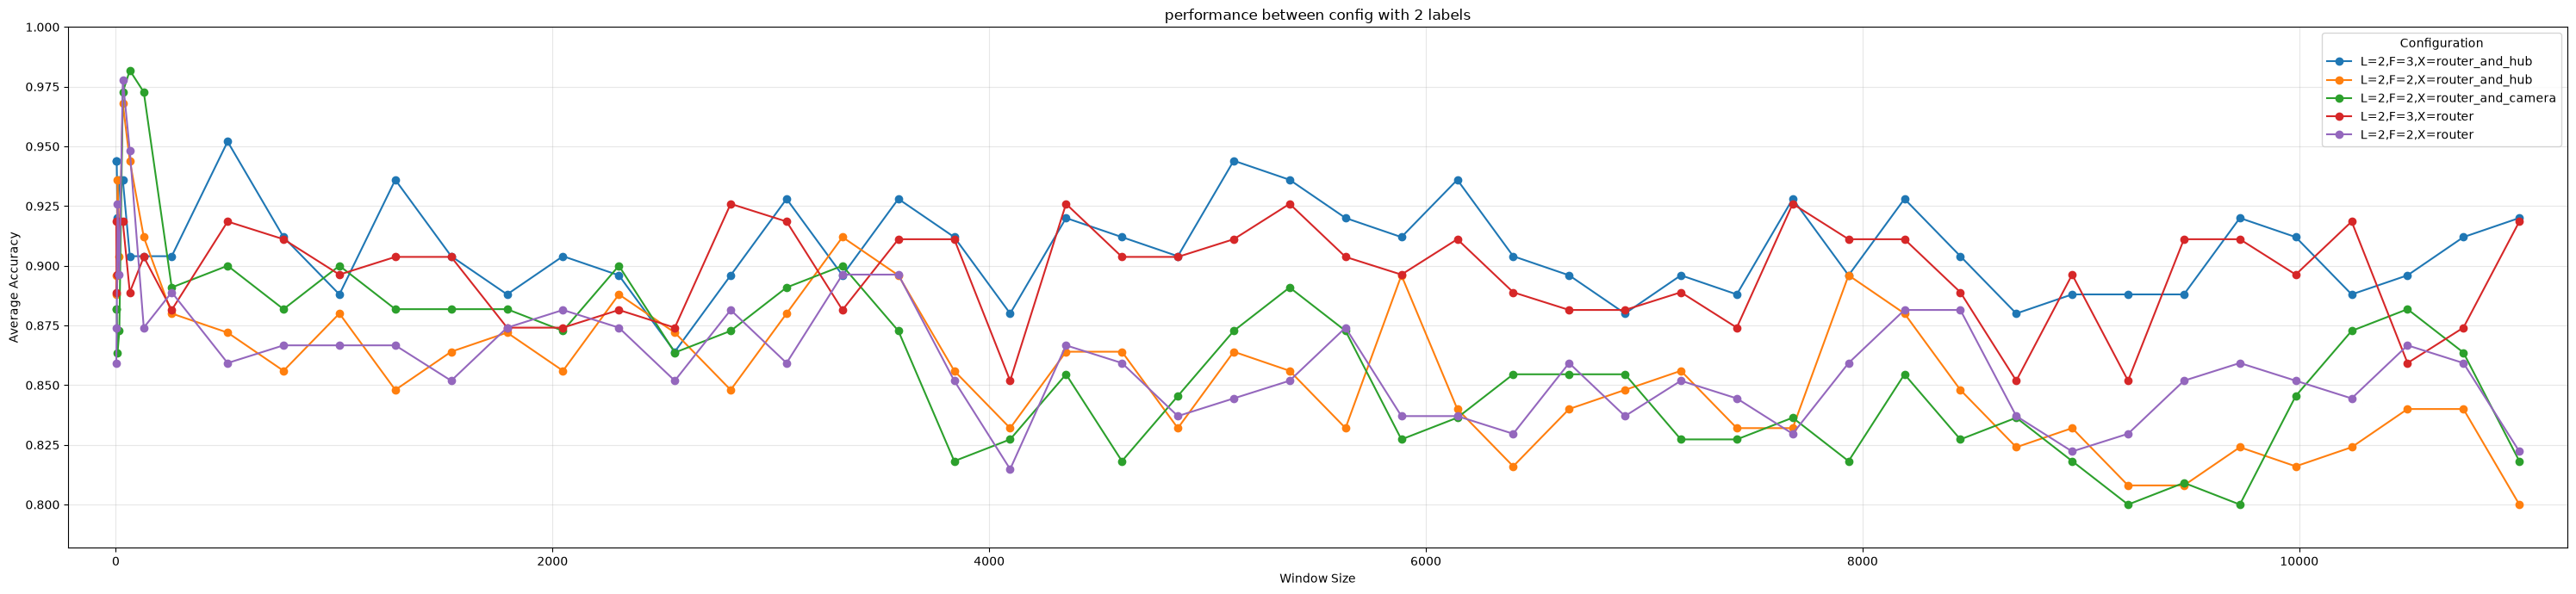

In [9]:
twoLabelsConfig = [config for config in configs_label if configs_label[config].get('L') == 2]
twoLabelConfigLabel = performance_summary[performance_summary['configuration'].isin(twoLabelsConfig)]
plot_performance(twoLabelConfigLabel, "performance between config with 2 labels")

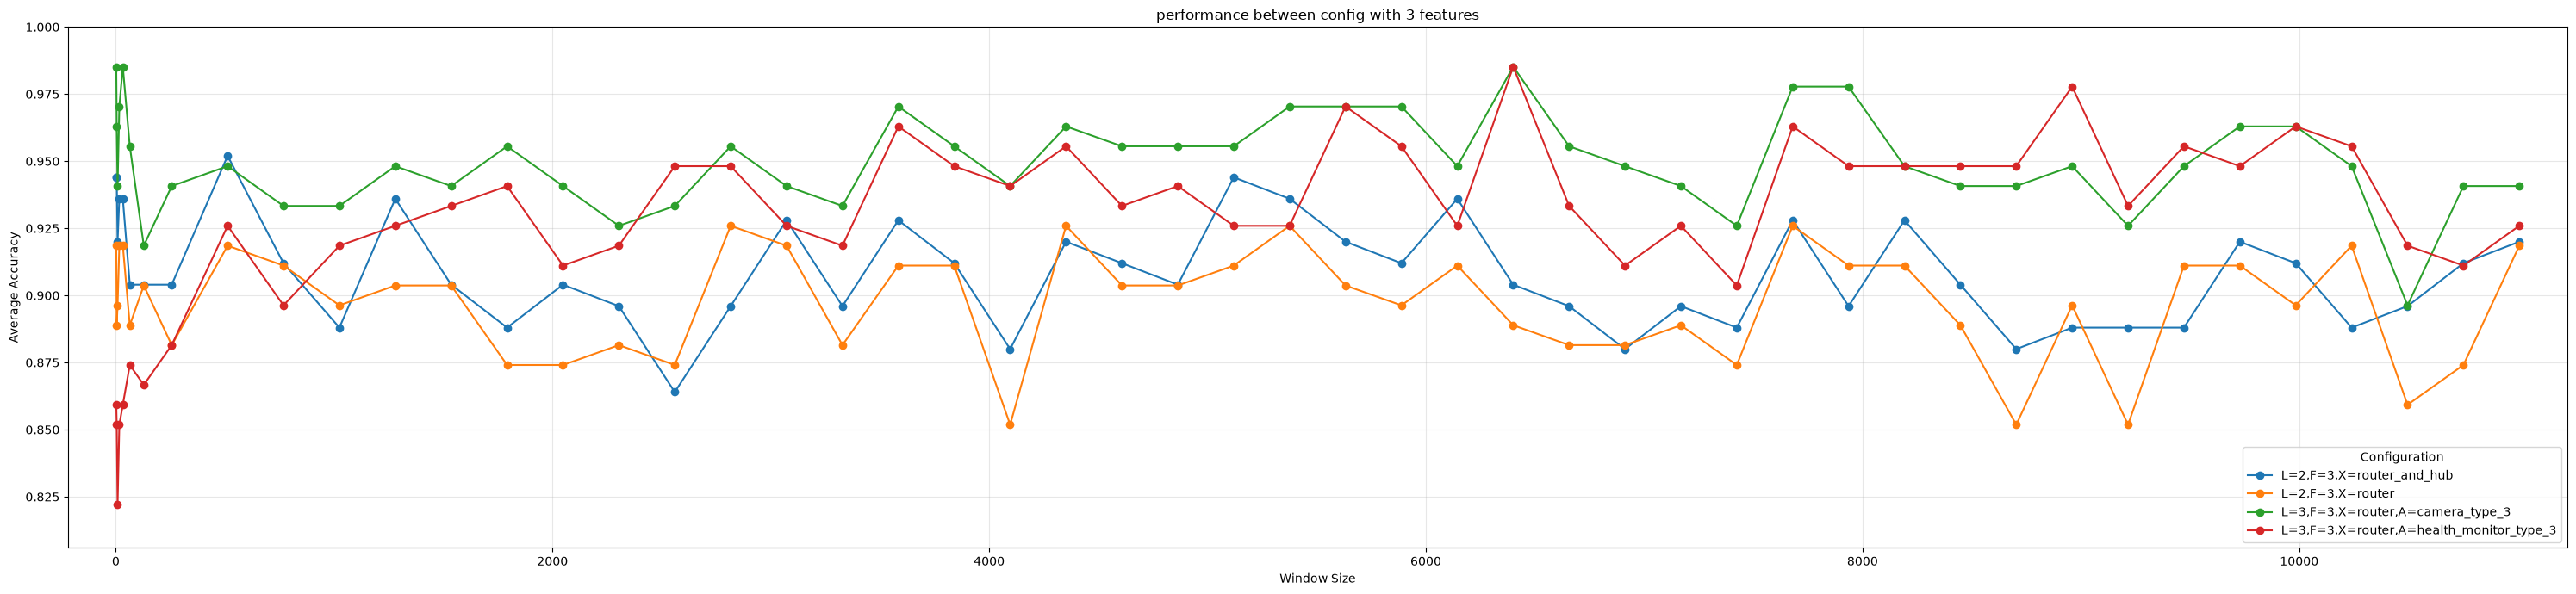

In [10]:
threeFeaturesConfig = [config for config in configs_label if configs_label[config].get('F') == 3]
threeFeaturesConfigLabel = performance_summary[performance_summary['configuration'].isin(threeFeaturesConfig)]
plot_performance(threeFeaturesConfigLabel, "performance between config with 3 features")

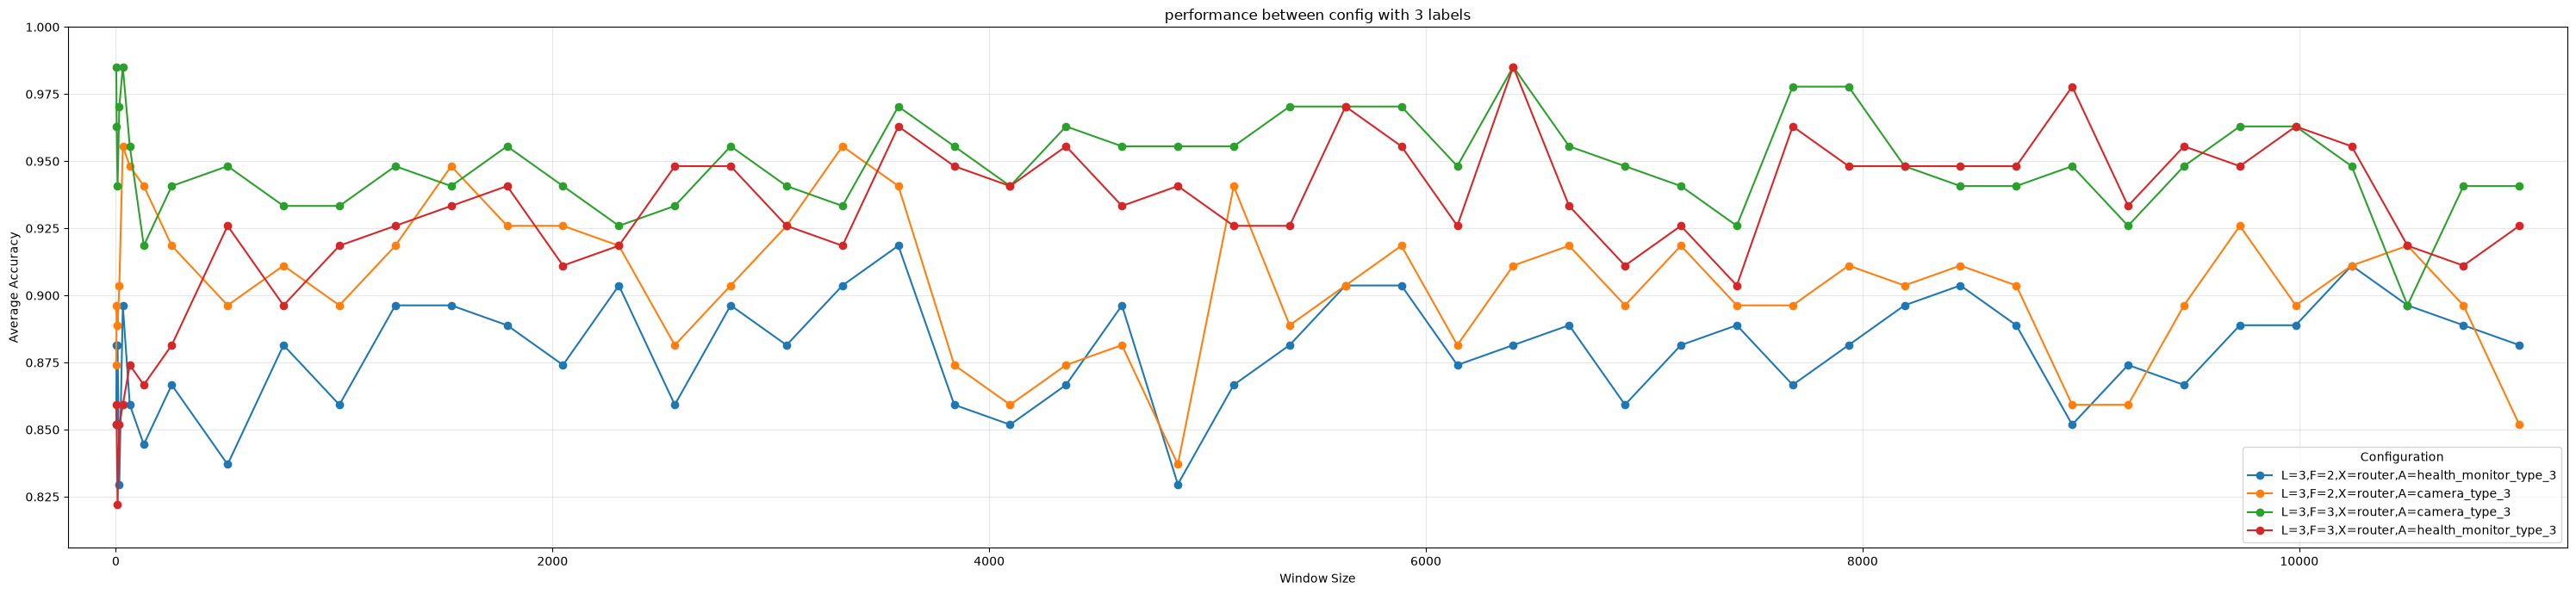

In [11]:
threeLabelsConfig = [config for config in configs_label if configs_label[config].get('L') == 3]
threeLabelConfigLabel = performance_summary[performance_summary['configuration'].isin(threeLabelsConfig)]
plot_performance(threeLabelConfigLabel, "performance between config with 3 labels")

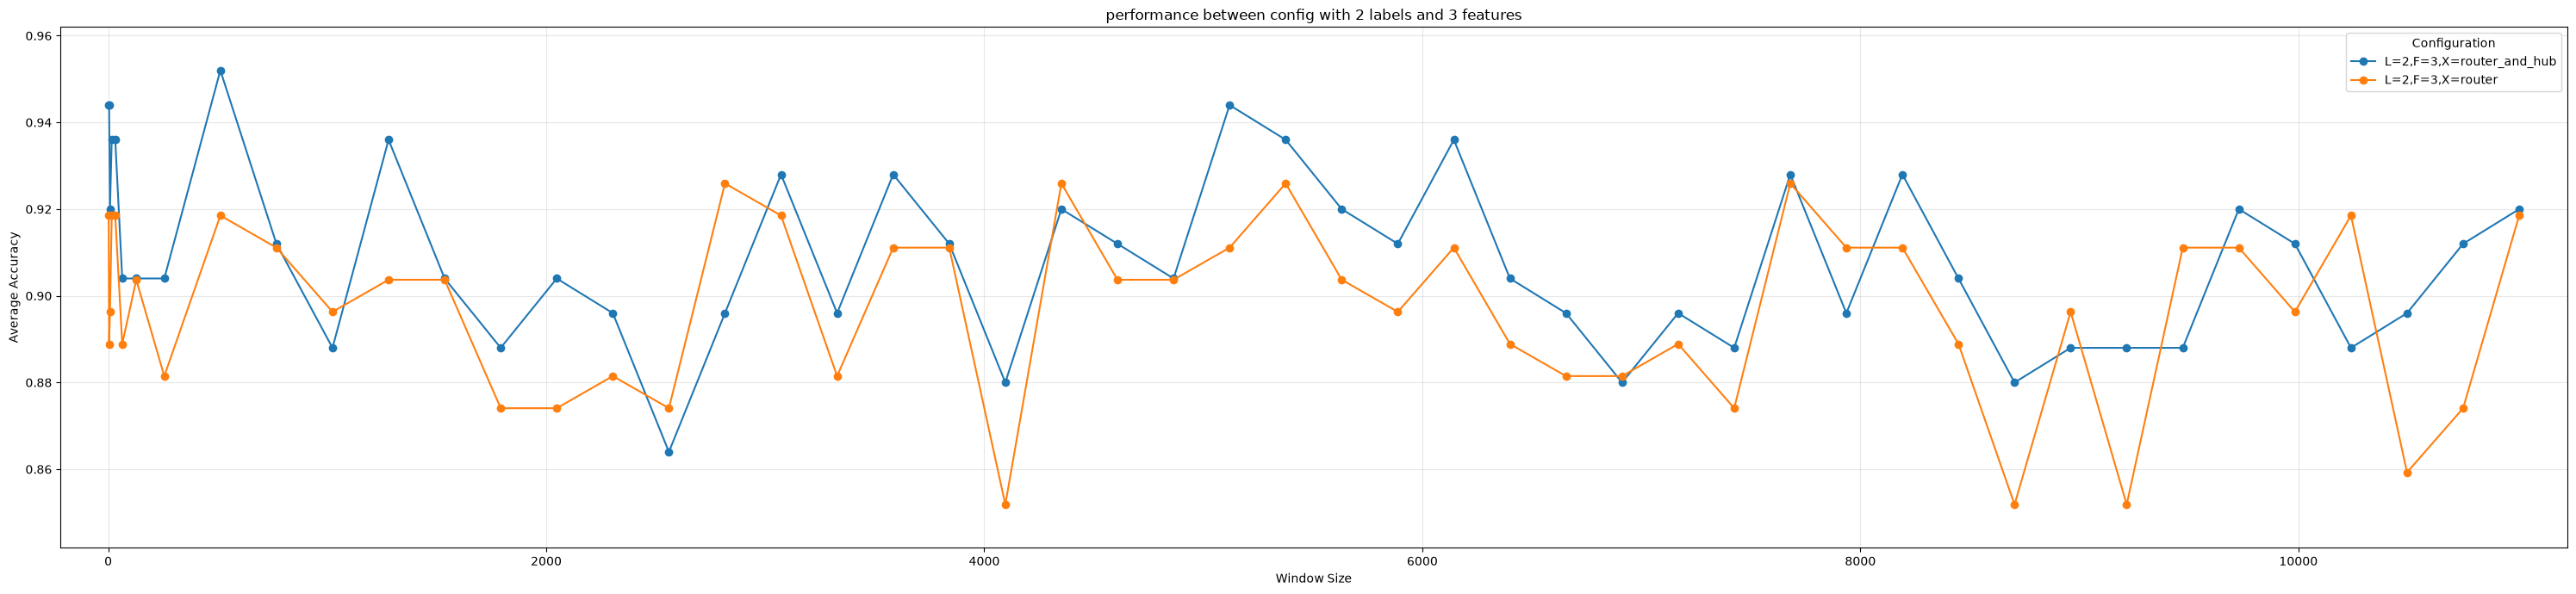

In [12]:
twoLabelsThreeFeaturesConfig = [config for config in configs_label if configs_label[config].get('L') == 2 and configs_label[config].get('F') == 3]
twoLabelsThreeFeaturesConfigLabel = performance_summary[performance_summary['configuration'].isin(twoLabelsThreeFeaturesConfig)]
plot_performance(twoLabelsThreeFeaturesConfigLabel, "performance between config with 2 labels and 3 features")

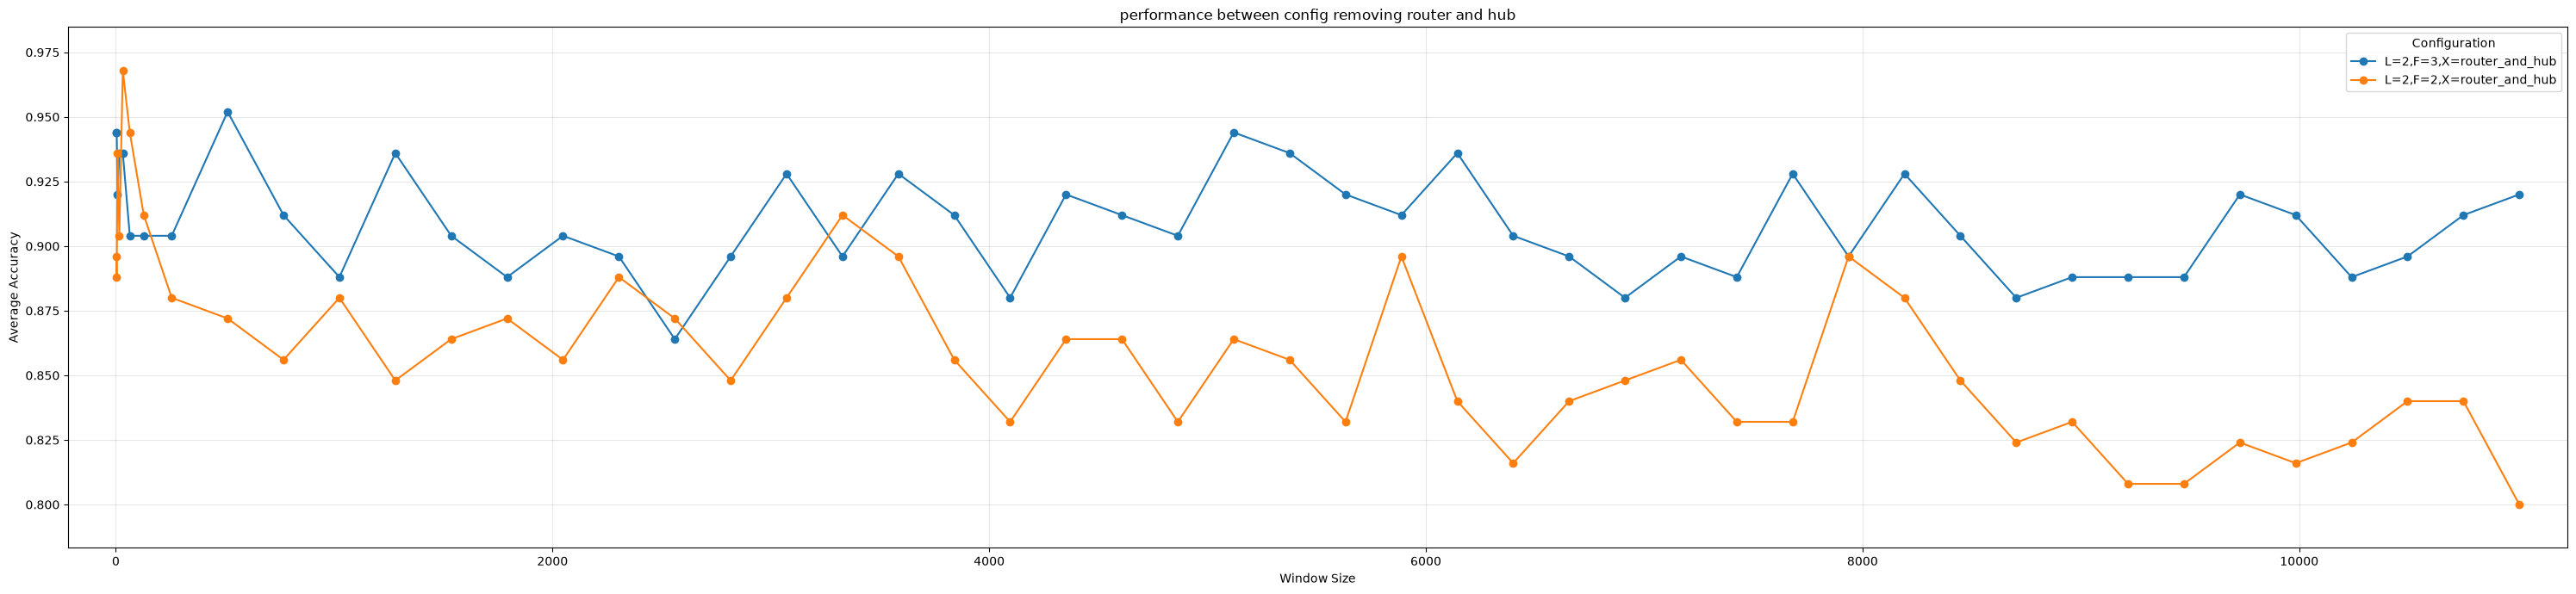

In [13]:
configRemovingRouterAndHub = [config for config in configs_label if configs_label[config].get('X') == "router_and_hub"]
configRemovingRouterAndHubLabel = performance_summary[performance_summary['configuration'].isin(configRemovingRouterAndHub)]
plot_performance(configRemovingRouterAndHubLabel, "performance between config removing router and hub")

,device_name,device,misclassification_count
0,IPhone,d0:a6:37:df:a1:e1,1272
1,Android Phone,40:f3:08:ff:1e:da,1168
2,Android Phone,b4:ce:f6:a7:a3:c2,1113
3,Samsung Galaxy Tab,08:21:ef:3b:fc:e3,771
4,MacBook,ac:bc:32:d4:6f:2f,674
5,Laptop,74:2f:68:81:69:42,445
6,Blipcare Blood Pressure meter,74:6a:89:00:2e:25,245
7,iHome,74:c6:3b:29:d7:1d,153
8,NEST Protect smoke alarm,18:b4:30:25:be:e4,102
9,Triby Speaker,18:b7:9e:02:20:44,60


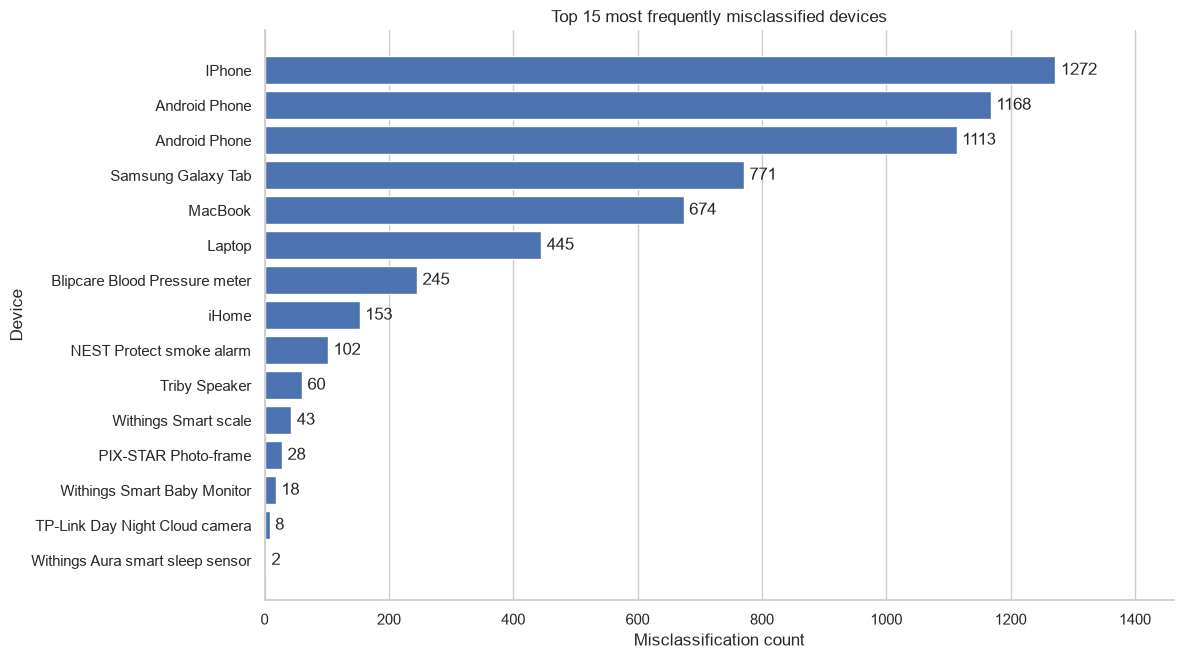

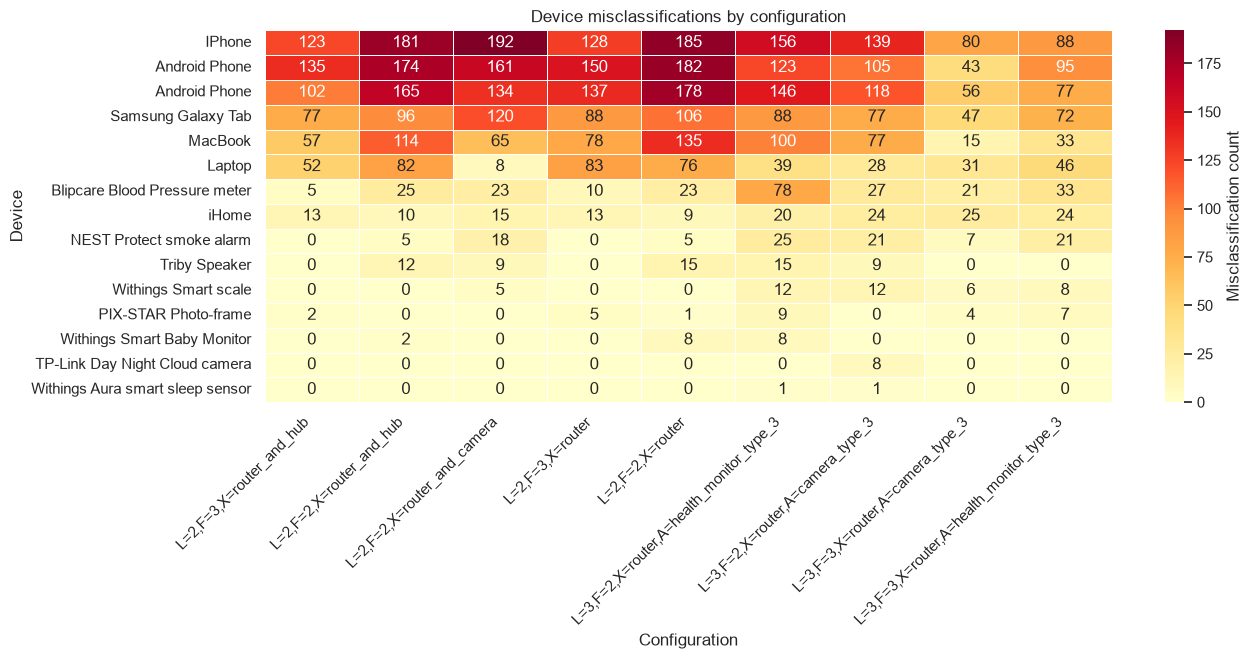

In [15]:
import ast
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PERFORMANCE_DIR = Path("performance-record")
TOP_N = 20

# Normalize MAC addresses for dictionary lookups.
device_lookup = {
    str(mac).strip().lower(): info
    for mac, info in device_dict_1.items()
}

def get_device_name(mac):
    info = device_lookup.get(str(mac).strip().lower(), {})
    return info.get("device_name") or mac

# Load raw results from every configuration.
csv_files = sorted(PERFORMANCE_DIR.glob("*.csv"))
if not csv_files:
    raise FileNotFoundError(f"No CSV files found in {PERFORMANCE_DIR}")

raw_results = pd.concat(
    [
        pd.read_csv(
            csv_file,
            usecols=["fold", "window_size", "misclassified_devices"],
        ).assign(configuration=csv_file.stem)
        for csv_file in csv_files
    ],
    ignore_index=True,
)

# Convert stored lists into one row per misclassified device.
misclassified = (
    raw_results
    .assign(
        device=raw_results["misclassified_devices"]
        .fillna("[]")
        .apply(ast.literal_eval)
    )
    .explode("device")
    .dropna(subset=["device"])
    .reset_index(drop=True)
)

misclassified["device"] = (
    misclassified["device"].astype(str).str.strip().str.lower()
)

# Keep MAC addresses as identifiers; use names only for display.
device_counts = (
    misclassified["device"]
    .value_counts()
    .rename_axis("device")
    .reset_index(name="misclassification_count")
)
device_counts["device_name"] = device_counts["device"].map(get_device_name)

display(device_counts[["device_name", "device", "misclassification_count"]])

if device_counts.empty:
    print("No misclassified devices found.")
else:
    counts_by_config = (
        misclassified
        .groupby(["device", "configuration"])
        .size()
        .unstack(fill_value=0)
        .reindex(
            index=device_counts["device"],
            columns=[file.stem for file in csv_files],
            fill_value=0,
        )
    )

    top_devices = device_counts.head(TOP_N)
    sns.set_theme(style="whitegrid")

    # 1. Horizontal bar chart
    fig, ax = plt.subplots(
        figsize=(12, max(5, len(top_devices) * 0.45))
    )

    positions = list(range(len(top_devices)))
    bars = ax.barh(
        positions,
        top_devices["misclassification_count"],
        color="#4C72B0",
    )

    ax.set_yticks(positions, labels=top_devices["device_name"])
    ax.invert_yaxis()
    ax.bar_label(bars, padding=4, fmt="%.0f")
    ax.set(
        title=f"Top {len(top_devices)} most frequently misclassified devices",
        xlabel="Misclassification count",
        ylabel="Device",
    )
    ax.margins(x=0.15)
    ax.grid(axis="y", visible=False)
    sns.despine(ax=ax)
    plt.tight_layout()
    plt.show()

    # 2. Heatmap comparing configurations
    heatmap_data = counts_by_config.reindex(
        top_devices["device"], fill_value=0
    )

    config_labels = [
        get_config_label(config)
        if callable(globals().get("get_config_label"))
        else config
        for config in heatmap_data.columns
    ]

    fig, ax = plt.subplots(
        figsize=(
            max(12, heatmap_data.shape[1] * 1.5),
            max(5, len(heatmap_data) * 0.45),
        )
    )

    sns.heatmap(
        heatmap_data,
        annot=True,
        fmt="d",
        cmap="YlOrRd",
        linewidths=0.5,
        xticklabels=config_labels,
        yticklabels=top_devices["device_name"].tolist(),
        cbar_kws={"label": "Misclassification count"},
        ax=ax,
    )

    ax.set(
        title="Device misclassifications by configuration",
        xlabel="Configuration",
        ylabel="Device",
    )
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    plt.setp(ax.get_yticklabels(), rotation=0)
    plt.tight_layout()
    plt.show()

# Note 
- Comparing without gateway
- Smaller sample size of window (i.e: 20 data points, < 2 or 3 hours)
- Clearer config
- Questions:
    - Why is smaller size window better?
    - Different label 3?
- How many misclassified devices? What are they?

# TO-DO:
- Generate around 20 to 30 data points, we can put a stop at 2 or 3 hours
- Define clearer labels in graph
- 